the useful info that i found from the distributions that monthly income is right skewd 

lets see the correlation between numerical features

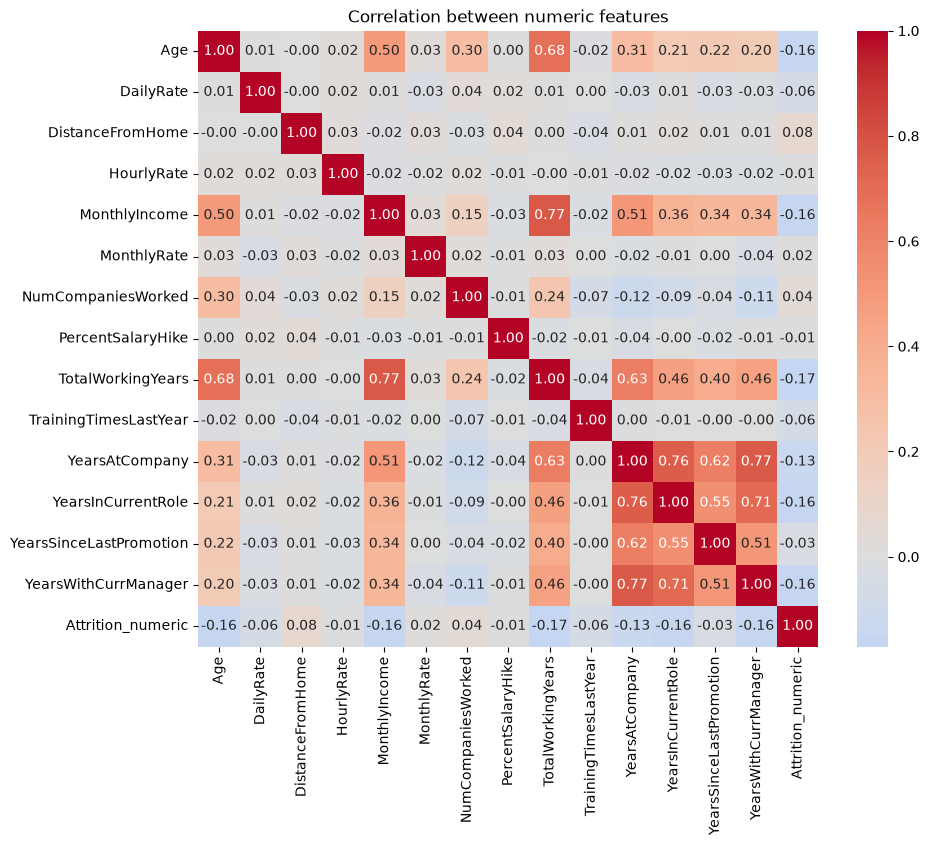

In [134]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()

we can see that :
- Monthly income has high correlation (0.77) with Total working years, 0.51 with YearsAtCompany and (0.5) with Age, which makes sense since salary goes up as careers advance 
- total working years, years at company, ... that red block in the right corner have high correlation which is also logical
- we notice that Age, Monthly income, total working years have negative correlation with attrition (-0.17), which is not high negative but can be considered 
- Distance from home have positive correlation (0.08) with attrition, can be studied

## Investegation by groups

we can split columns into categories, and make an analysis for each category alone

In [135]:
column_groups = {
    "Compensation": [
        "HourlyRate", "DailyRate", "MonthlyRate",
        "MonthlyIncome", "PercentSalaryHike", "StockOptionLevel"
    ],

    "Career History": [
        "TotalWorkingYears", "YearsAtCompany",
        "YearsInCurrentRole", "YearsSinceLastPromotion",
        "YearsWithCurrManager", "NumCompaniesWorked"
    ],

    "Education and Development": [
        "Education", "EducationField", # "TrainingTimesLastYear" we will handle this column in a seperate way.
    ],

    "Demographics and Personal Life": [
        "Age", "Gender", "MaritalStatus"
    ],

    "Job and Satisfaction": [
        "EnvironmentSatisfaction", "JobInvolvement",
        "JobLevel", "JobRole", "JobSatisfaction",
        "PerformanceRating", "WorkLifeBalance"
    ],

    "Work Conditions": [
        "OverTime", "BusinessTravel", "DistanceFromHome"
    ],

    "Organization": [
        "Department"
    ],
}

lets plot the data considering Attrition to get better understanding of it

In [178]:
from pandas.api.types import is_numeric_dtype

def plot_category(
    df,
    column_groups,
    category,
    target="Attrition",
    n_cols=3
):
    if category not in column_groups:
        available = ", ".join(column_groups.keys())
        raise ValueError(
            f"Unknown category '{category}'. Available categories: {available}"
        )

    columns = [
        column for column in column_groups[category]
        if column in df.columns and column != target
    ]

    if not columns:
        raise ValueError(f"No valid columns found for '{category}'.")

    n_rows = math.ceil(len(columns) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6 * n_cols, 4.5 * n_rows)
    )

    axes = np.atleast_1d(axes).flatten()

    for index, column in enumerate(columns):
        ax = axes[index]

        if is_numeric_dtype(df[column]):
            # Numerical columns: compare distributions by attrition
            sns.boxplot(
                data=df,
                x=target,
                y=column,
                hue=target,
                palette=color_map,
                legend=False,
                ax=ax
            )
            ax.set_xlabel("Attrition")
            ax.set_ylabel(column)

        else:
            # Categorical columns: compare attrition counts
            sns.countplot(
                data=df,
                x=column,
                hue=target,
                palette=color_map,
                ax=ax
            )
            ax.set_xlabel(column)
            ax.set_ylabel("Employee Count")
            ax.tick_params(axis="x", rotation=45)

        ax.set_title(f"{column} vs {target}")

    # Remove unused subplot axes
    for ax in axes[len(columns):]:
        fig.delaxes(ax)

    fig.suptitle(f"{category} Analysis", fontsize=16)
    plt.tight_layout()
    plt.show()

    # return fig, axes


from IPython.display import display


def display_category_tables(
    df,
    column_groups,
    category,
    target="Attrition"
):
    columns = [
        column for column in column_groups[category]
        if column in df.columns and column != target
    ]

    for column in columns:
        table = pd.crosstab(df[column], df[target])
        table = table.reindex(columns=["No", "Yes"], fill_value=0)

        table["Total"] = table["No"] + table["Yes"]
        table["AttritionRate"] = (
            table["Yes"] / table["Total"] * 100
        ).round(2)

        table = table.reset_index()
        table.columns.name = None
        table = table.rename(columns={column: column})
        table = table.sort_values('AttritionRate')
        print(f"\n{column}")
        display(table)

### Compensation

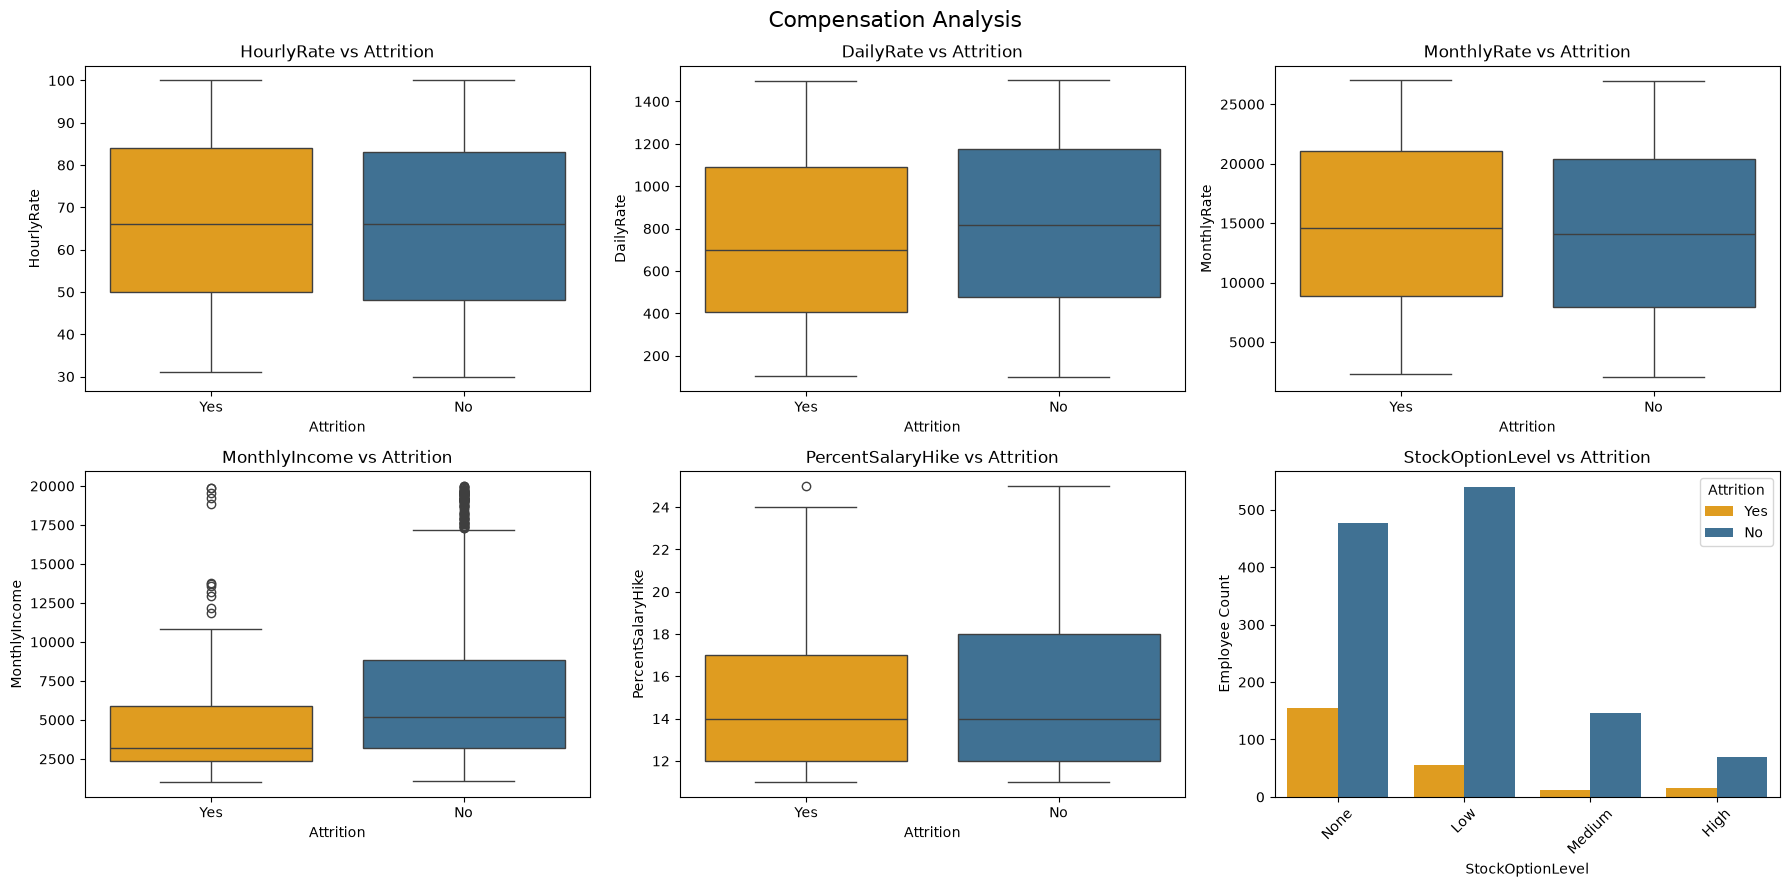

In [137]:
plot_category(df,column_groups,"Compensation")

In [180]:
stock_summary = (
    df.assign(Left=df["Attrition"].eq("Yes"))
      .groupby("StockOptionLevel", observed=True)
      .agg(
          Employees=("Left", "size"),
          EmployeesLeft=("Left", "sum"),
          AttritionRate=("Left", "mean")
      )
      .assign(AttritionRate=lambda x: x["AttritionRate"].mul(100))
      .reset_index()
)

stock_summary.sort_values('AttritionRate')

,StockOptionLevel,Employees,EmployeesLeft,AttritionRate
2,Medium,158,12,7.594937
1,Low,596,56,9.395973
3,High,85,15,17.647059
0,None,631,154,24.405705


- The distributions of HourlyRate, DailyRate, MonthlyRate, and PercentSalaryHike appear similar for employees who stayed and those who left. Therefore, no strong association with attrition is apparent from these plots.

- Employees who left have a lower MonthlyIncome than employees who stayed. This suggests that lower income may be associated with higher attrition

- Employees with no stock options had a 24.4% attrition rate, compared with 16.1% overall. Employees with low or medium stock options had lower attrition rates. The high-stock-option group had a smaller sample and its attrition rate was closer to the overall rate, so the relationship is not strictly linear.

### Career History

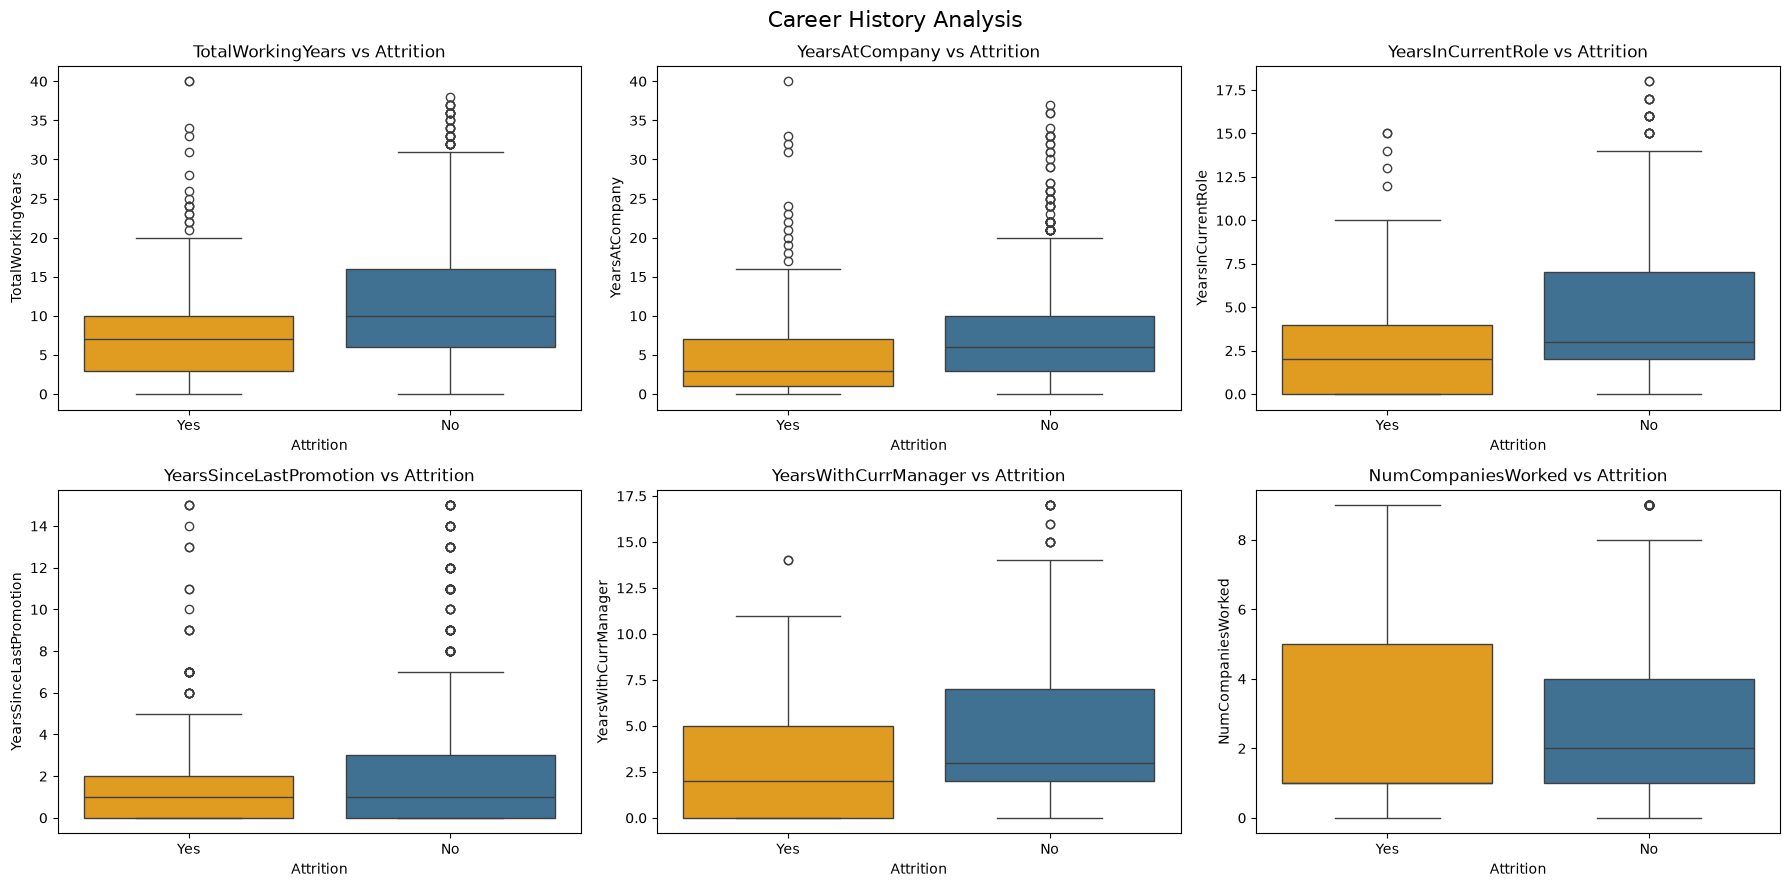

In [139]:
plot_category(df,column_groups,"Career History")

Employees with fewer years at the company generally show higher attrition rates. However, this is an observed association, not proof that shorter tenure causes employees to leave.

### Education and Development

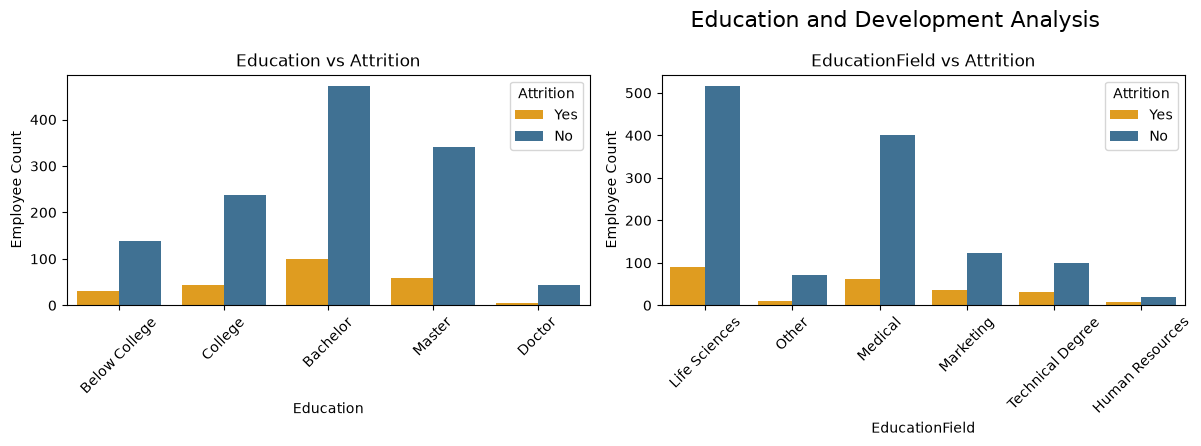

In [140]:
plot_category(df,column_groups,"Education and Development")

In [181]:
display_category_tables(df,column_groups,"Education and Development")


Education


,Education,No,Yes,Total,AttritionRate
4,Doctor,43,5,48,10.42
3,Master,340,58,398,14.57
1,College,238,44,282,15.60
2,Bachelor,473,99,572,17.31
0,Below College,139,31,170,18.24



EducationField


,EducationField,No,Yes,Total,AttritionRate
4,Other,71,11,82,13.41
3,Medical,401,63,464,13.58
1,Life Sciences,517,89,606,14.69
2,Marketing,124,35,159,22.01
5,Technical Degree,100,32,132,24.24
0,Human Resources,20,7,27,25.93


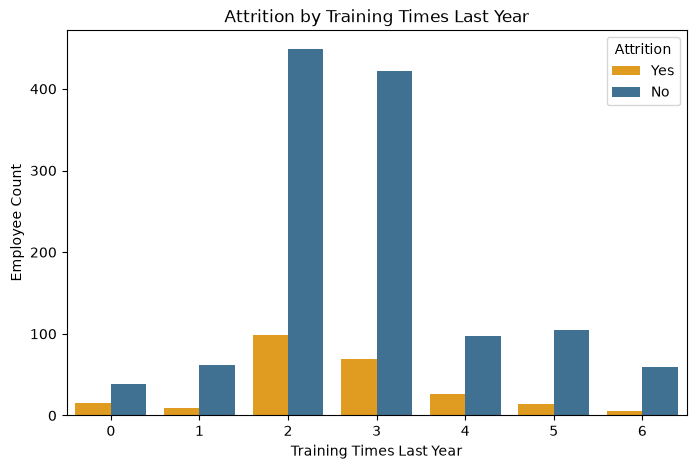

In [142]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="TrainingTimesLastYear",
    hue="Attrition",
    palette=color_map
)

plt.xlabel("Training Times Last Year")
plt.ylabel("Employee Count")
plt.title("Attrition by Training Times Last Year")
plt.show()

In [182]:
training_summary = (
    df.assign(Left=df["Attrition"].eq("Yes"))
      .groupby("TrainingTimesLastYear")["Left"]
      .agg(
          Employees="size",
          EmployeesLeft="sum",
          AttritionRate="mean"
      )
      .assign(
          AttritionRate=lambda table: table["AttritionRate"].mul(100)
      )
      .reset_index()
)

training_summary.sort_values("AttritionRate")

,TrainingTimesLastYear,Employees,EmployeesLeft,AttritionRate
6,6,65,6,9.230769
5,5,119,14,11.764706
1,1,71,9,12.676056
3,3,491,69,14.052953
2,2,547,98,17.915905
4,4,123,26,21.138211
0,0,54,15,27.777778


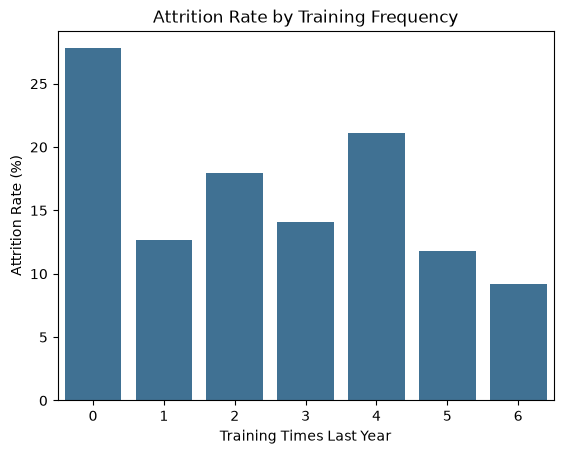

In [144]:
sns.barplot(
    data=training_summary,
    x="TrainingTimesLastYear",
    y="AttritionRate",
    color="#3274A1"
)

plt.ylabel("Attrition Rate (%)")
plt.xlabel("Training Times Last Year")
plt.title("Attrition Rate by Training Frequency")
plt.show()

Attrition rates are relatively similar across education levels, Education Fields and Training times last year, so this dataset does not show a strong association between an employee’s education and attrition.

- Attrition is fairly close to our baseline across education levels (10.4%–18.2%).
-Education field varies more than Education Level: Technical Degree 24.2% , Marketing 22.0% and HR 25.9% (only 7 left out of 27..) vs about 13.4%–14.7% for Life Sciences, Medical and Other. 
- Training frequency shows no steady pattern

### Demographics and Personal Life

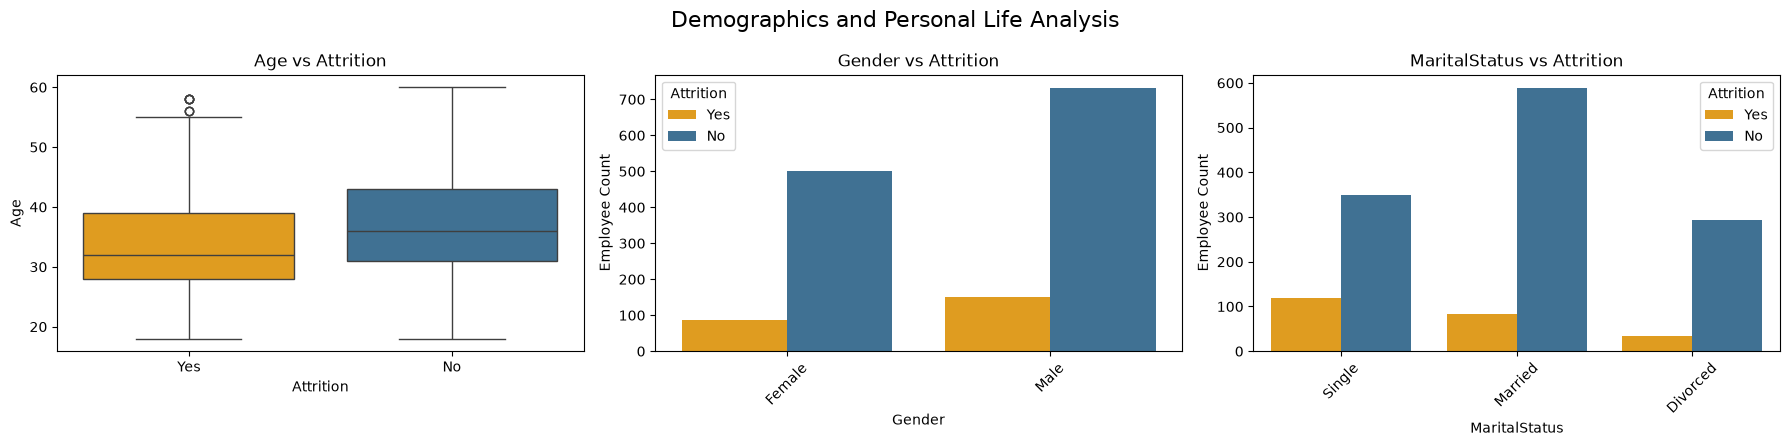

In [146]:
plot_category(df,column_groups,"Demographics and Personal Life")


In [147]:
display_category_tables(df,column_groups,"Demographics and Personal Life")



Age


,Age,No,Yes,Total,AttritionRate
0,18,4,4,8,50.00
1,19,3,6,9,66.67
2,20,5,6,11,54.55
3,21,7,6,13,46.15
4,22,11,5,16,31.25
5,23,10,4,14,28.57
6,24,19,7,26,26.92
7,25,20,6,26,23.08
8,26,27,12,39,30.77
9,27,45,3,48,6.25



Gender


,Gender,No,Yes,Total,AttritionRate
0,Female,501,87,588,14.80
1,Male,732,150,882,17.01



MaritalStatus


,MaritalStatus,No,Yes,Total,AttritionRate
0,Divorced,294,33,327,10.09
1,Married,589,84,673,12.48
2,Single,350,120,470,25.53


- Marital status: 25.5% of Single employees left (120 of 470), vs 12.5% of Married and 10.1% of Divorced, compared with 16.1% overall. Singles are 32% of employees but 51% of leavers (120 of 237).
- Gender: 17.0% of men vs 14.8% of women left, a small difference.

### Job and Satisfaction

- Sales Representatives have high attrition rate than all other Roles - (39.8%)  vs 16.1% overall- HR and Laboratory Tech have around 23% attrition rate which is high, others are normal in our comparasion.
- Entry level left at 26.3% vs 4.7%–14.7% for the other levels.
- Performance rating has only two values (3 and 4), with 16.1% vs 16.4%, so it has almost no variation to learn from.
- Work-life balance: "Bad" working condition have high attrition rate (31.2%). The other three are 14.2%–17.6% with no steady trend.
- Low Job Satsfaction have 22.84% attrition rate
- Low Job Involvement have 33.73% attrition rate


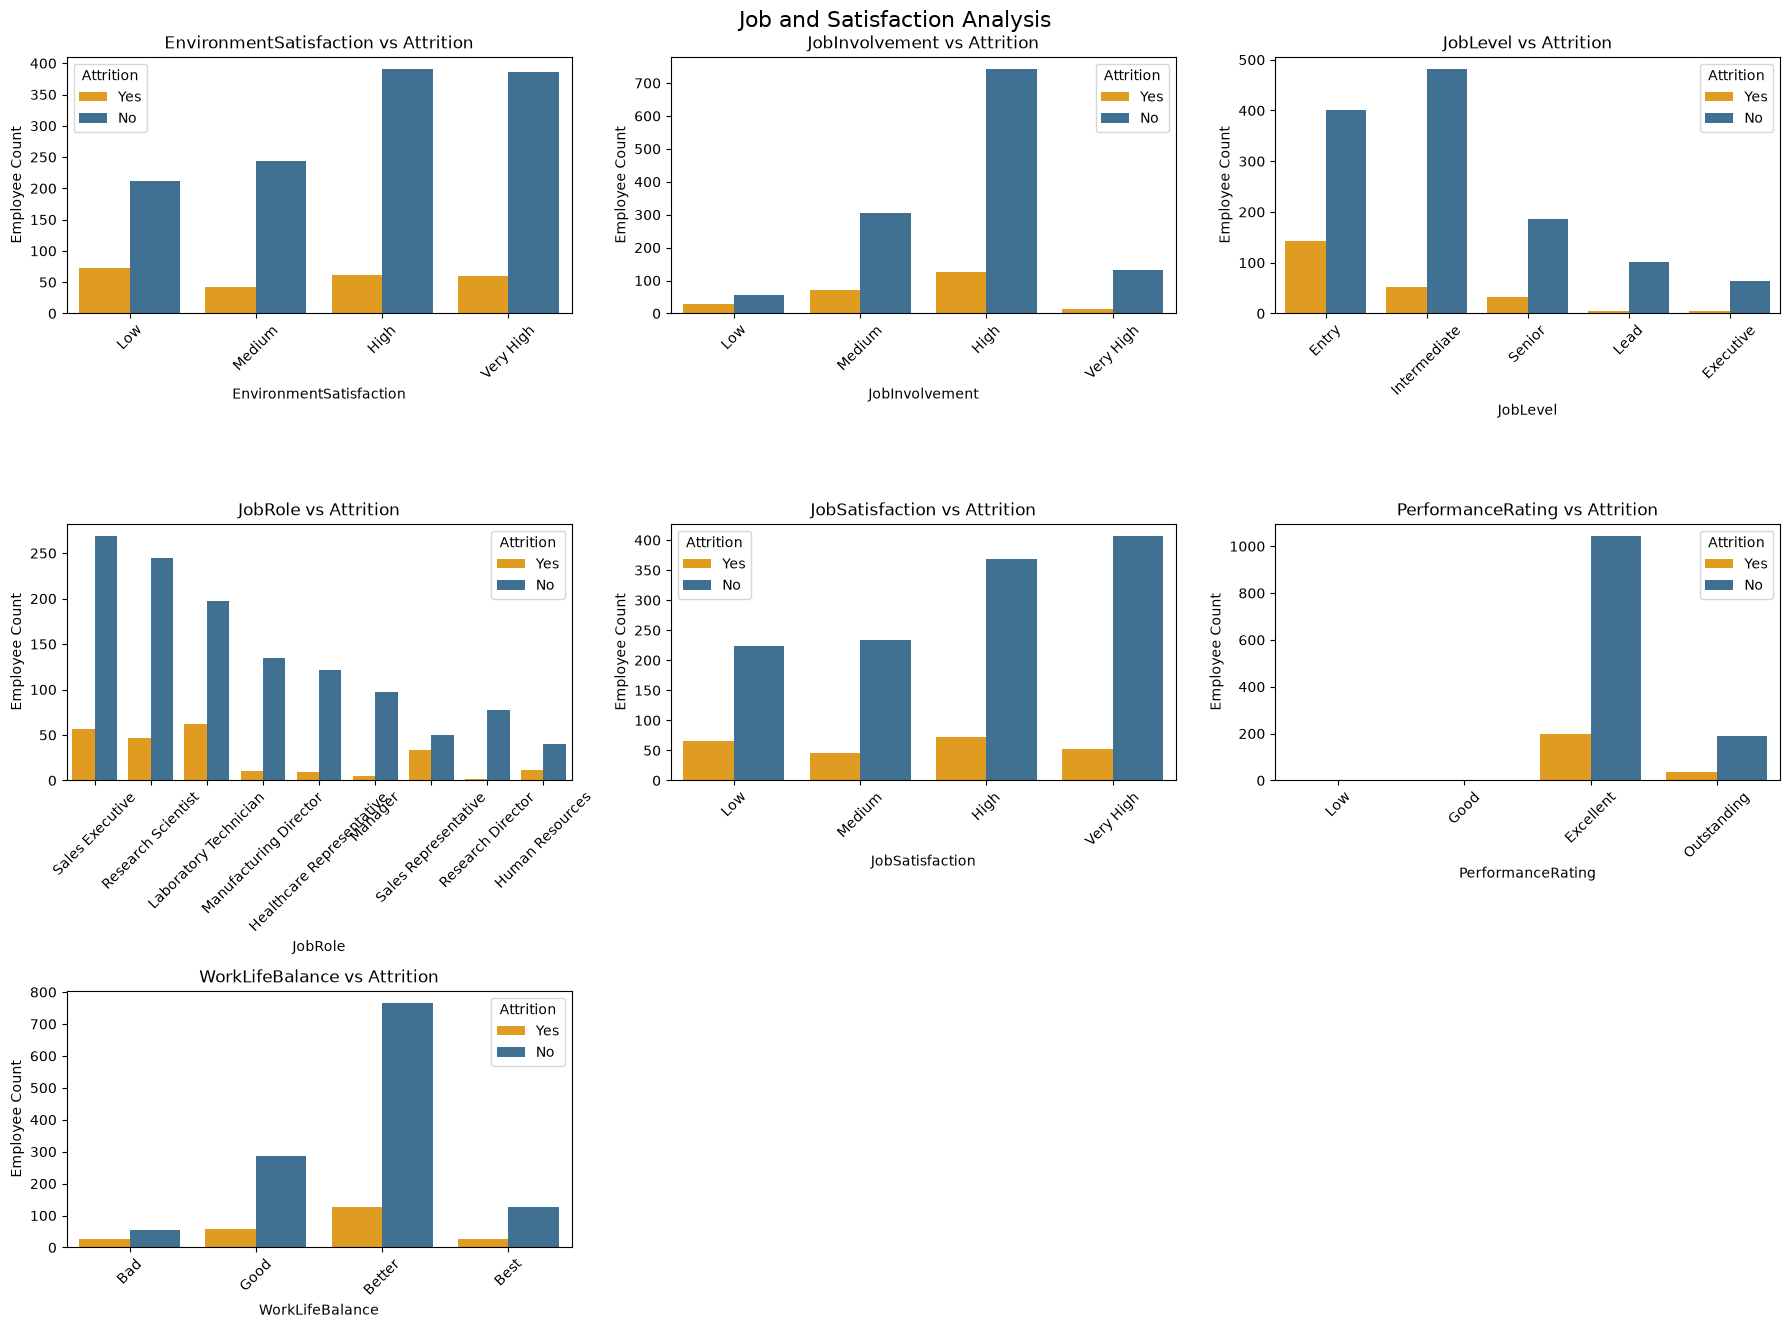

In [148]:
plot_category(df,column_groups,"Job and Satisfaction")


In [149]:
display_category_tables(df,column_groups,"Job and Satisfaction")



EnvironmentSatisfaction


,EnvironmentSatisfaction,No,Yes,Total,AttritionRate
0,Low,212,72,284,25.35
1,Medium,244,43,287,14.98
2,High,391,62,453,13.69
3,Very High,386,60,446,13.45



JobInvolvement


,JobInvolvement,No,Yes,Total,AttritionRate
0,Low,55,28,83,33.73
1,Medium,304,71,375,18.93
2,High,743,125,868,14.40
3,Very High,131,13,144,9.03



JobLevel


,JobLevel,No,Yes,Total,AttritionRate
0,Entry,400,143,543,26.34
1,Intermediate,482,52,534,9.74
2,Senior,186,32,218,14.68
3,Lead,101,5,106,4.72
4,Executive,64,5,69,7.25


... (4 outputs left out)


PerformanceRating


,PerformanceRating,No,Yes,Total,AttritionRate
0,Excellent,1044,200,1244,16.08
1,Outstanding,189,37,226,16.37



WorkLifeBalance


,WorkLifeBalance,No,Yes,Total,AttritionRate
0,Bad,55,25,80,31.25
1,Good,286,58,344,16.86
2,Better,766,127,893,14.22
3,Best,126,27,153,17.65


### Work Conditions

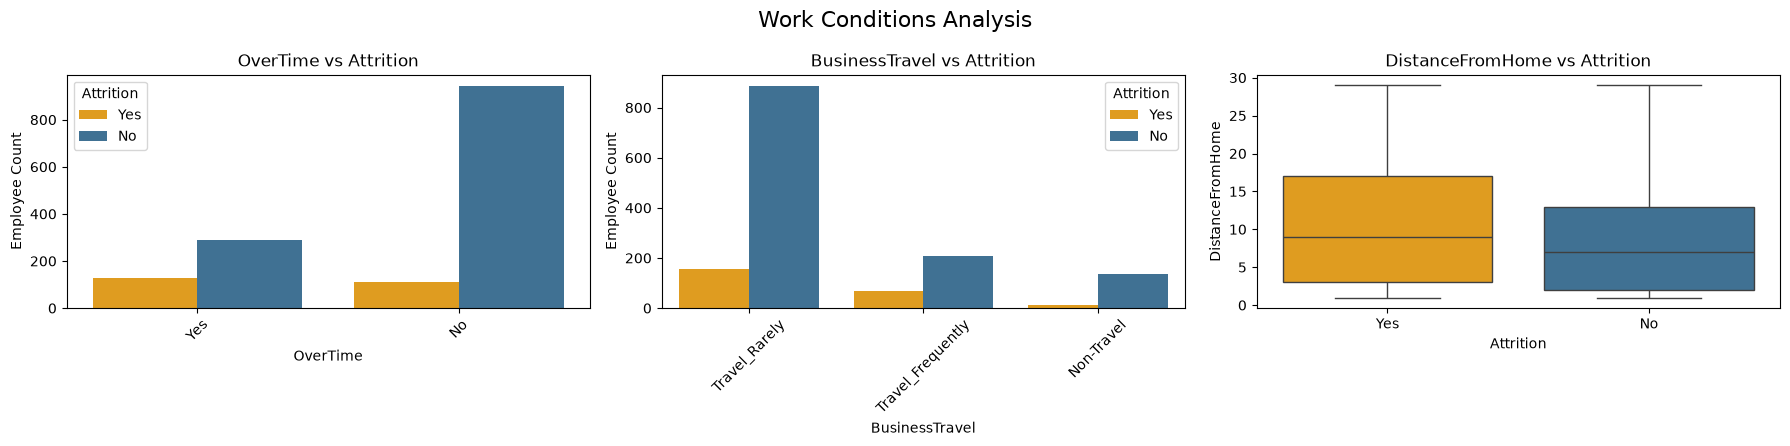

In [150]:
plot_category(df,column_groups,"Work Conditions")


In [157]:
display_category_tables(df,column_groups,"Work Conditions")


OverTime


,OverTime,No,Yes,Total,AttritionRate
0,No,944,110,1054,10.44
1,Yes,289,127,416,30.53



BusinessTravel


,BusinessTravel,No,Yes,Total,AttritionRate
0,Non-Travel,138,12,150,8.00
1,Travel_Frequently,208,69,277,24.91
2,Travel_Rarely,887,156,1043,14.96



DistanceFromHome


,DistanceFromHome,No,Yes,Total,AttritionRate
0,1,182,26,208,12.50
1,2,183,28,211,13.27
2,3,70,14,84,16.67
3,4,55,9,64,14.06
4,5,55,10,65,15.38
5,6,52,7,59,11.86
6,7,73,11,84,13.10
7,8,70,10,80,12.50
8,9,67,18,85,21.18
9,10,75,11,86,12.79


- Overtime: 30.5% of employees working overtime left (416) vs 10.4% without (1054), against a 16.1% baseline.
- Business travel: Travel_Frequently 24.9% (277), Travel_Rarely 15.0% (1043), Non-Travel 8.0% (150).

### Organization

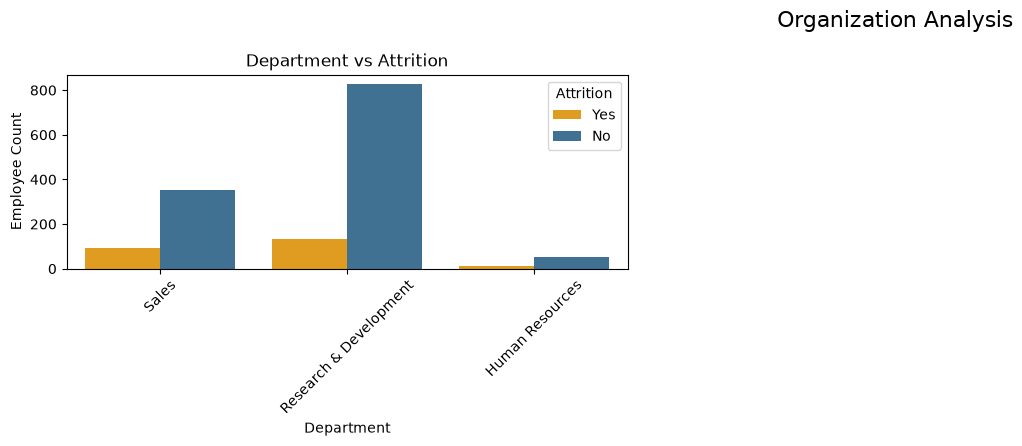

In [151]:
plot_category(df,column_groups,"Organization")


In [152]:
display_category_tables(df,column_groups, "Organization")


Department


,Department,No,Yes,Total,AttritionRate
0,Human Resources,51,12,63,19.05
1,Research & Development,828,133,961,13.84
2,Sales,354,92,446,20.63


Sales attrition rate is 20.6% (446 total, 92 left), HR is 19.0% (63 total, 12 left) and R&D at 13.8% (961 total, 133 left), against 16.1% overall. Sales and HR are above the baseline and R&D is below it.

In [185]:
income_by_level = (df.groupby(["JobLevel", "Attrition"], observed=True)["MonthlyIncome"]
                     .agg(["count", "median","mean"]).unstack())
income_by_level

count        median                   mean              
Attrition       No  Yes       No      Yes            No           Yes
JobLevel                                                             
Entry          400  143   2719.0   2437.0   2854.407500   2598.125874
Intermediate   482   52   5334.5   5346.0   5474.495851   5759.788462
Senior         186   32   9982.5   9887.0   9891.032258   9388.406250
Lead           101    5  16307.0  13194.0  15620.287129  13150.400000
Executive       64    5  19199.5  19545.0  19170.578125  19463.800000

Leavers earn less overall, but they are concentrated in Entry level, where pay is low for everyone (143 of 237 leavers). Within Intermediate, Senior and Executive levels the median incomes of leavers and stayers are almost identical. Only Entry level shows a gap (2,437 vs 2,719). So the pay–attrition link is mostly a job-level effect. (Lead shows a bigger gap, but only 5 employees left there, so it isn't reliable.)

In [186]:
df["TenureBucket"] = pd.cut(df["YearsAtCompany"], bins=[-1, 1, 3, 5, 10, 40],
                            labels=["0-1", "2-3", "4-5", "6-10", "10+"])
tenure = df.groupby("TenureBucket", observed=True)["Attrition_numeric"].agg(
    Employees="size", AttritionRate="mean")
tenure["AttritionRate"] *= 100
tenure.round(1)

,Employees,AttritionRate
TenureBucket,,
0-1,215,34.9
2-3,255,18.4
4-5,306,13.1
6-10,448,12.3
10+,246,8.1


## Key Findings
Baseline: 16.1% of employees left (237 of 1,470).
1. Overtime is the strongest single signal: 30.5% of employees working overtime left (n = 416) vs 10.4% without (n = 1,054).
2. Early tenure is high risk: 34.9% of employees with 0–1 years at the company left (n = 215), falling to 8.1% after 10+ years (n = 246).
3. Entry-level jobs carry most of the attrition: 26.3% (n = 543), and 143 of the 237 leavers. By role, Sales Representatives left at 39.8% (n = 83) and Laboratory Technicians at 23.9% (n = 259), vs 2.5% for Research Directors (n = 80).
4. The pay–attrition link is mostly a job-level effect: leavers earn less overall, but within Intermediate, Senior and Executive levels incomes are almost identical.
5. Other groups with higher attrition: Single employees (25.5%, n = 470), frequent business travelers (24.9%, n = 277) and employees with no stock options (24.4%, n = 631). These overlap with early-career employees.
6. Little signal: HourlyRate, DailyRate, MonthlyRate, PercentSalaryHike, PerformanceRating and Gender.